In [1]:
import ast
import copy
import csv
import re

import dask.dataframe as dd
import numpy as np
import pandas as pd
import seaborn as sns
from Bio import SeqIO
from Bio.Seq import Seq
from matplotlib import pyplot as plt

In [2]:
def align_read(querystr, cigarstr, pattern=re.compile("[0-9]{0,10}[MDI]")):
    result = pattern.finditer(cigarstr)
    cigar_seq = [(item.group(0)[-1], int(item.group(0)[:-1])) for item in result]
    #     output_str = "".join(["-" for i in range(cigar[1])])
    output_str = ""
    current_idx = 0
    for item in cigar_seq:
        if item[0] == "M":
            added_str = querystr[current_idx : current_idx + item[1]]
            output_str += added_str
            current_idx += item[1]
        elif item[0] == "D":
            added_str = "".join(["-" for i in range(item[1])])
            output_str += added_str
        elif item[0] == "I":
            current_idx += item[1]
    return output_str


def cigarsfromsam(samfilepath):
    cigars = {}
    with open(samfilepath, "r") as samfile:
        for line in samfile:
            if line[0] == "@":
                next(samfile)
            else:
                splitline = line.split("\t")
                cigars[splitline[0]] = splitline[5]
    return cigars


def strsfromfasta(fastafilepath):
    queries = SeqIO.to_dict(SeqIO.parse(fastafilepath, "fasta"))
    queries = {key: str(val.seq) for key, val in queries.items()}
    return queries


def make_seg_dict(gfafile):
    segment_dict = {}
    with open(gfafile, "r") as infile:
        for line in infile:
            if line[0] == "S":
                splitline = line.split("\t")
                segment_dict[splitline[1]] = splitline[2][:-1]
    return segment_dict


def get_ref_intervals(gfafile):
    segment_dict = {}
    current_idx = 0
    with open(gfafile, "r") as infile:
        for line in infile:
            if line[0] == "S":
                splitline = line.split("\t")
                if "OFF" not in splitline[1]:
                    refstr = splitline[2][:-1]
                    strlen = len(refstr)
                    name = splitline[1]
                    if "ON" in name:
                        name = name[:-2]
                    segment_dict[name] = tuple((current_idx, current_idx + strlen))
                    current_idx += strlen
    return segment_dict


def align_read(
    querystr, refstr, cigarstr, startpos=1, pattern=re.compile("[0-9]{0,10}[MDI]")
):
    start_pos = startpos - 1  ##comes as 1 indexed from minimap
    result = pattern.finditer(cigarstr)
    cigar_seq = [(item.group(0)[-1], int(item.group(0)[:-1])) for item in result]
    #     output_str = "".join(["-" for i in range(cigar[1])])
    output_str = ""
    if start_pos > 0:
        output_str += "".join(["-" for i in range(start_pos)])
    current_idx = 0
    for item in cigar_seq:
        if item[0] == "M":
            added_str = querystr[current_idx : current_idx + item[1]]
            output_str += added_str
            current_idx += item[1]
        elif item[0] == "D":
            added_str = "".join(["-" for i in range(item[1])])
            output_str += added_str
        elif item[0] == "I":
            current_idx += item[1]
    remaining_len = len(refstr) - len(output_str)
    if remaining_len > 0:
        output_str += "".join(["-" for i in range(remaining_len)])
    return output_str


def splitstr(instr, ref_intervals):
    strassign = {key: instr[val[0] : val[1]] for key, val in ref_intervals.items()}
    return strassign


def slow_hamming_distance(s1, s2):
    if len(s1) != len(s2):
        print(s1, s2)
        raise ValueError("Strand lengths are not equal!")
    term_list = []
    for ch1, ch2 in zip(s1, s2):
        if ch1 == "N" or ch2 == "N":
            term_list.append(False)
        else:
            term_list.append(ch1 != ch2)
    result = sum(term_list)
    return result


def get_dict_dist(dict1, dict2):
    hamming_dict = {
        key: slow_hamming_distance(dict1[key], dict2[key]) for key in dict1.keys()
    }
    return hamming_dict

In [3]:
data = pd.read_csv(
    "/home/lag36/scratch/lag36/2024-11-22_lLAG10_Nanopore/output.tsv",
    # "/home/lag36/scratch/lag36/2024-02-12_lLAG2_Nanopore-Promethion_genome_Run_2/output_subsample=None.tsv",
    delimiter="\t",
).drop(columns = 'Unnamed: 0')

ref_intervals = get_ref_intervals("/home/lag36/scratch/lag36/2024-11-22_lLAG10_Nanopore/ref_lLAG8.gfa")
barcodes = set(data["barcode"].tolist())

In [4]:
data

,barcodeid,barcode,consensus,reference,alignmentstart,cigar,subsample
0,0,000000000000000000000100110011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,607M2D482M,NaN
1,1,000000000000000000001101111011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN
2,2,000000000000000000100101010101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,925M1I166M,NaN
3,3,000000000000000001010010100010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN
4,4,000000000000000001100011111000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN
...,...,...,...,...,...,...,...
452938,452938,111111111000110001010001111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,379M1I184M1I395M1I133M,NaN
452939,452939,111111111001001011011011000000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,560M2D529M,NaN
452940,452940,111111111001101101111011100100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,575M1I516M,NaN
452941,452941,111111111101100000001011111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,379M1D201M1I510M,NaN


In [5]:
bit_arr = np.array([list(item) for item in barcodes]).astype("uint8")
bit_freq = np.mean(bit_arr, axis=0)

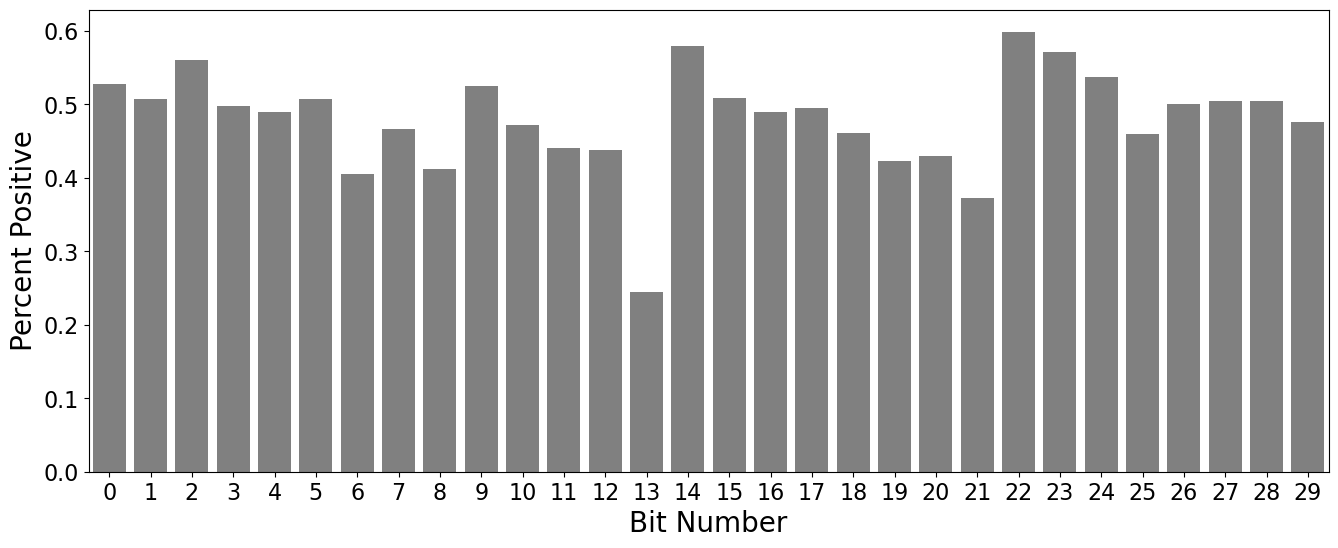

In [6]:
fig = plt.figure(figsize=(16, 6))
sns.barplot(x=list(range(len(bit_freq))), y=bit_freq, color="grey")
plt.xlabel("Bit Number", fontsize=20)
plt.ylabel("Percent Positive", fontsize=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# plt.savefig(
#     "/home/lag36/gutiloluis/2024-01-26_lLAG2_Nanopore_Primordium-Reads/figure_1.png",
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

In [7]:
# import os
# import shutil
# import time
# from time import sleep

# import dask
# import dask.array as da
# import h5py
# from dask.distributed import Client, progress
# from dask_jobqueue import SLURMCluster
# from IPython.core.display import HTML, display


# def writedir(directory, overwrite=False):
#     if overwrite:
#         if os.path.exists(directory):
#             shutil.rmtree(directory)
#         os.makedirs(directory)
#     else:
#         if not os.path.exists(directory):
#             os.makedirs(directory)


# class tr_dask_controller:  # adapted from Charles' code
#     def __init__(
#         self,
#         n_workers=6,
#         local=True,
#         queue="short",
#         death_timeout=3.0,
#         walltime="01:30:00",
#         cores=1,
#         processes=1,
#         memory="6GB",
#         working_directory="./",
#         job_extra=[],
#     ):
#         self.local = local
#         self.n_workers = n_workers
#         self.walltime = walltime
#         self.queue = queue
#         self.death_timeout = death_timeout
#         self.processes = processes
#         self.memory = memory
#         self.cores = cores
#         self.working_directory = working_directory
#         self.job_extra = job_extra

#         writedir(working_directory, overwrite=False)

#     def startdask(self):
#         if self.local:
#             self.daskclient = Client()
#             self.daskclient.cluster.scale(self.n_workers)
#         else:
#             self.daskcluster = SLURMCluster(
#                 n_workers=self.n_workers,
#                 queue=self.queue,
#                 death_timeout=self.death_timeout,
#                 walltime=self.walltime,
#                 processes=self.processes,
#                 memory=self.memory,
#                 cores=self.cores,
#                 local_directory=self.working_directory,
#                 log_directory=self.working_directory,
#                 job_extra=self.job_extra,
#             )
#             #             self.workers = self.daskcluster.start_workers(self.n_workers)
#             self.daskclient = Client(self.daskcluster)

#     def shutdown(self):
#         self.daskclient.restart()
#         if not self.local:
#             self.daskcluster.close()
#         for item in os.listdir(self.working_directory):
#             if "worker-" in item or "slurm-" in item or ".lock" in item:
#                 path = "./" + item
#                 if os.path.isfile(path):
#                     os.remove(path)
#                 elif os.path.isdir(path):
#                     shutil.rmtree(path)

#     def printprogress(self):
#         complete = len([item for item in self.futures if item.status == "finished"])
#         print(str(complete) + "/" + str(len(self.futures)))

#     def displaydashboard(self):
#         link = self.daskcluster.dashboard_link
#         display(HTML('<a href="' + link + '">Dashboard</a>'))

#     def mapfovs(self, function, fov_list, retries=0):
#         self.function = function
#         self.retries = retries

#         def mapallfovs(fov_number, function=function):
#             function(fov_number)

#         self.futures = {}
#         for fov in fov_list:
#             future = self.daskclient.submit(mapallfovs, fov, retries=retries)
#             self.futures[fov] = future

#     def retry_failed(self):
#         self.failed_fovs = [
#             fov for fov, future in self.futures.items() if future.status != "finished"
#         ]
#         out = self.daskclient.restart()
#         self.mapfovs(self.function, self.failed_fovs, retries=self.retries)

#     def retry_processing(self):
#         self.proc_fovs = [
#             fov for fov, future in self.futures.items() if future.status == "pending"
#         ]
#         out = self.daskclient.restart()
#         self.mapfovs(self.function, self.proc_fovs, retries=self.retries)

In [3]:
import os
import shutil
import dask
import time
import h5py
import threading
import dask.distributed

from time import sleep
from dask.distributed import Client,progress
from dask.distributed.diagnostics.plugin import WorkerPlugin
from dask_jobqueue import SLURMCluster
from IPython.core.display import display, HTML


# import os
# import shutil
# import time
# from time import sleep

# import dask
import dask.array as da
# import h5py
# from dask.distributed import Client, progress
# from dask_jobqueue import SLURMCluster
# from IPython.core.display import HTML, display

# from .utils import writedir
def writedir(directory,overwrite=False):
    if overwrite:
        if os.path.exists(directory):
            shutil.rmtree(directory)
        os.makedirs(directory)
    else:
        if not os.path.exists(directory):
            os.makedirs(directory)

## Hacky memory trim
import ctypes
import gc

def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

class dask_controller: #adapted from Charles' code
    def __init__(self,n_workers=6,n_workers_min=6,local=True,queue="short",death_timeout=60.,\
                 walltime='01:00:00',cores=1,processes=1,memory='6GB',\
                 working_directory="./",job_extra_directives=[]):
        self.local = local
        self.n_workers = n_workers
        self.n_workers_min = n_workers_min
        self.walltime = walltime
        self.queue = queue
        self.death_timeout = death_timeout
        self.processes = processes
        self.memory = memory
        self.cores = cores
        self.working_directory = working_directory
        self.job_extra_directives = job_extra_directives

        self.futures = {}

        split_walltime = walltime.split(":")
        wall_hrs,wall_mins,wall_secs = tuple(split_walltime)
        ttl_wall_mins = (60*int(wall_hrs)) + int(wall_mins)

        if ttl_wall_mins < 10:
            raise ValueError("Walltime must be at least 10 mins long!")

        self.lifetime = str(max(ttl_wall_mins-10,10)) + "m"
        print(self.lifetime)
        print(walltime)
        self.worker_extra_args = ["--lifetime", self.lifetime, "--lifetime-stagger", "5m"]

        writedir(working_directory,overwrite=False)

    def startdask(self):
        if self.local:
            self.daskclient = Client()
            self.daskclient.cluster.scale(self.n_workers)
        else:
            self.daskcluster = SLURMCluster(n_workers=self.n_workers_min,queue=self.queue,death_timeout=self.death_timeout,walltime=self.walltime,\
                                   processes=self.processes,memory=self.memory,cores=self.cores,local_directory=self.working_directory,\
                                log_directory=self.working_directory,worker_extra_args=self.worker_extra_args,job_extra_directives=self.job_extra_directives)
            self.daskcluster.adapt(minimum=self.n_workers_min, maximum=self.n_workers,\
                                   interval="1m",wait_count=10)
            self.daskclient = Client(self.daskcluster)

    def shutdown(self, delete_files=True):
        self.reset_worker_memory()
        if not self.local:
            self.daskcluster.close()
        if delete_files:
            for item in os.listdir(self.working_directory):
                if "worker-" in item or "slurm-" in item or ".lock" in item:
                    path = "./" + item
                    if os.path.isfile(path):
                        os.remove(path)
                    elif os.path.isdir(path):
                        shutil.rmtree(path)

    def printprogress(self):
        complete = len([item for item in self.futures if item.status=="finished"])
        print(str(complete) + "/" + str(len(self.futures)))

    def displaydashboard(self):
        link = self.daskcluster.dashboard_link
        display(HTML('<a href="' + link +'">Dashboard</a>'))

    def mapfovs(self,function,fov_list,retries=0):
        self.function = function
        self.retries = retries
        def mapallfovs(fov_number,function=function):
            function(fov_number)
        self.futures = {}
        for fov in fov_list:
            future = self.daskclient.submit(mapallfovs,fov,retries=retries)
            self.futures[fov] = future

    def retry_failed(self):
        self.failed_fovs = [fov for fov,future in self.futures.items() if future.status != 'finished']
        out = self.daskclient.restart()
        self.mapfovs(self.function,self.failed_fovs,retries=self.retries)

    def retry_processing(self):
        self.proc_fovs = [fov for fov,future in self.futures.items() if future.status == 'pending']
        out = self.daskclient.restart()
        self.mapfovs(self.function,self.proc_fovs,retries=self.retries)

    def restart(self):
        self.daskclient.restart()
        with self.failure_lock:
            self.failure_counter_variable.set(0)

    def reset_worker_memory(self):
        self.daskclient.cancel([val for key,val in self.futures.items()])
        self.daskclient.run(gc.collect)
        self.daskclient.run(trim_memory)
        print("Done.")

class hdf5lock:
    def __init__(self,filepath,updateperiod=0.1):
        self.filepath = filepath
        self.lockfile = filepath + ".lock"
        self.updateperiod = updateperiod

    def _lock(self):
        while True:
            if not os.path.exists(self.lockfile):
                open(self.lockfile,'w').close()
                break
            sleep(self.updateperiod)

    def _apply_fn(self,function,iomode,*args,**kwargs):
        try:
            fn_output = function(self.filepath,iomode,*args,**kwargs)
            os.remove(self.lockfile)
            return fn_output
        except:
            os.remove(self.lockfile)
            raise

    def lockedfn(self,function,iomode,*args,**kwargs):
        self._lock()
        fn_output = self._apply_fn(function,iomode,*args,**kwargs)
        return fn_output

def transferjob(sourcedir,targetdir,single_file=False):
    mkdircmd = "mkdir -p '" + targetdir + "'"
    if single_file:
        rsynccmd = "rsync -r '" + sourcedir + "' '" + targetdir + "'"
    else:
        rsynccmd = "rsync -r '" + sourcedir + "/' '" + targetdir + "'"
    wrapcmd = mkdircmd + " && " + rsynccmd
    cmd = "sbatch -p transfer -t 0-12:00 --wrap=\"" + wrapcmd + "\""
    print(cmd)
    os.system(cmd)


/tmp/ipykernel_51738/3156986082.py:13: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


In [9]:
print(1)

1


In [10]:
dask_controller_ = dask_controller(
    walltime="02:00:00",
    # walltime="02:00:00",
    local=False,
    n_workers=10,#10,
    memory="16GB",#"32GB", # 
    working_directory="/home/lag36/scratch/lag36/dask",
)

dask_controller_.startdask()
dask_controller_.displaydashboard()

110m
02:00:00


In [11]:
# dask_bit_arr = da.from_array(bit_arr, chunks=(10000, 30)).astype("uint8")

In [12]:
dask_bit_arr = da.from_array(bit_arr, chunks=(10000, 30)).astype("uint8")

In [13]:
dask_bit_arr

dask.array<array, shape=(452943, 30), dtype=uint8, chunksize=(10000, 30), chunktype=numpy.ndarray>

In [14]:
n_chunks = 5
step = dask_bit_arr.chunksize[0] * n_chunks

closest_match_list = []

for i in range(0, dask_bit_arr.shape[0], step):
    both_on = (dask_bit_arr[i : i + step] @ dask_bit_arr.T).astype("uint8")
    both_off = ((-dask_bit_arr + 1)[i : i + step] @ (-dask_bit_arr.T + 1)).astype(
        "uint8"
    )
    ttl_match = both_on + both_off
    hamming_dist = dask_bit_arr.shape[1] - ttl_match

    N = hamming_dist.shape[0]
    M = hamming_dist.shape[1]
    K = max(0, dask_bit_arr.shape[0] - (i + step))
    if (i > 0) and (K > 0):
        zeros_arr_left = da.zeros((N, i)).astype(bool)
        zeros_arr_right = da.zeros((N, K)).astype(bool)
        diagonal_mask = da.eye(N).astype(bool)
        padded_diagonal_mask = da.concatenate(
            [zeros_arr_left, diagonal_mask, zeros_arr_right], axis=1
        )
    elif i > 0:
        zeros_arr_left = da.zeros((N, i)).astype(bool)
        diagonal_mask = da.eye(N).astype(bool)
        padded_diagonal_mask = da.concatenate([zeros_arr_left, diagonal_mask], axis=1)
    else:
        zeros_arr_right = da.zeros((N, K)).astype(bool)
        diagonal_mask = da.eye(N).astype(bool)
        padded_diagonal_mask = da.concatenate([diagonal_mask, zeros_arr_right], axis=1)

    hamming_dist[padded_diagonal_mask] = 100
    closest_match = da.min(hamming_dist, axis=1)
    closest_match_list.append(closest_match.compute())

closest_match_list = np.concatenate(closest_match_list)

In [15]:
with open(
    "./closest_match.npy",
    "wb",
) as f:
    np.save(f, closest_match_list)

In [16]:
dask_controller_.shutdown()

Done.


2025-05-14 17:40:24,035 - distributed.client - ERROR - Failed to reconnect to scheduler after 30.00 seconds, closing client


In [4]:
with open(
    "./closest_match.npy",
    "rb",
) as f:
    closest_match_list = np.load(f)

In [5]:
closest_match_dict = {
    barcode: closest_match_list[k] for k, barcode in enumerate(barcodes)
}

NameError: name 'barcodes' is not defined

#### These are not the plots we want in the final draft

The final distribution should come from the bit-subtracted histograms extractable from the final pandas df

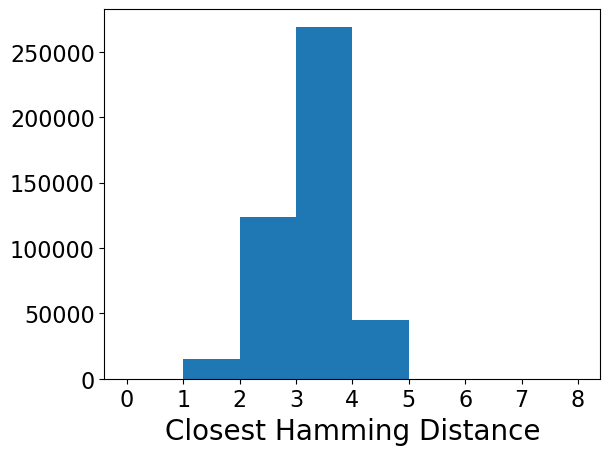

In [19]:
plt.hist(closest_match_list, bins=range(0, 9))
plt.xlabel("Closest Hamming Distance", fontsize=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
# plt.savefig("./figure_2.png",dpi=300,bbox_inches="tight")
plt.show()

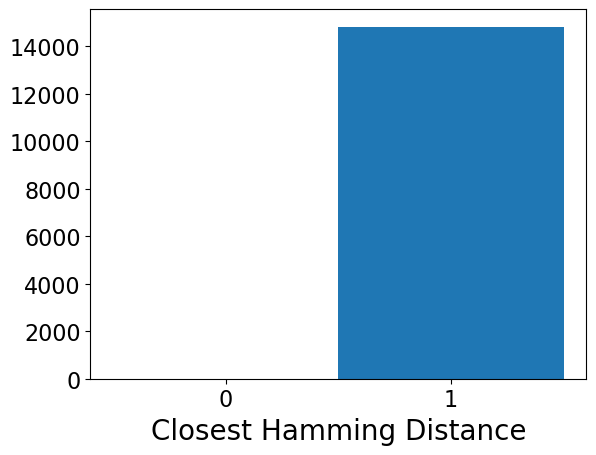

In [20]:
plt.hist(closest_match_list, range=(0, 1), bins=2)
plt.xlabel("Closest Hamming Distance", fontsize=20)
plt.xticks([0.25, 0.75], [0, 1], fontsize=16)
plt.yticks(fontsize=16)
# plt.savefig("./figure_3.png",dpi=300,bbox_inches="tight")
plt.show()

### Depth Distribution

In [7]:
headpath = "/home/lag36/scratch/lag36/2024-11-22_lLAG10_Nanopore/"

In [33]:
import pickle as pkl

import scipy as sp

with open(
    headpath + 'graph_output/barcode_counts_dict.pkl',
    # "/home/lag36/scratch/lag36/2024-02-12_lLAG2_Nanopore-Promethion_genome_Run_2/graph_output/barcode_counts_dict.pkl",
    "rb",
) as infile:
    depth_dict = pkl.load(infile)

In [34]:
depth_arr = np.array(list(depth_dict.values()))

In [35]:
data["barcode depth"] = data["barcode"].apply(lambda x: depth_dict[x])

NameError: name 'data' is not defined

In [ ]:
data['closest_match'] = data['barcode'].apply(lambda x: closest_match_dict[x])

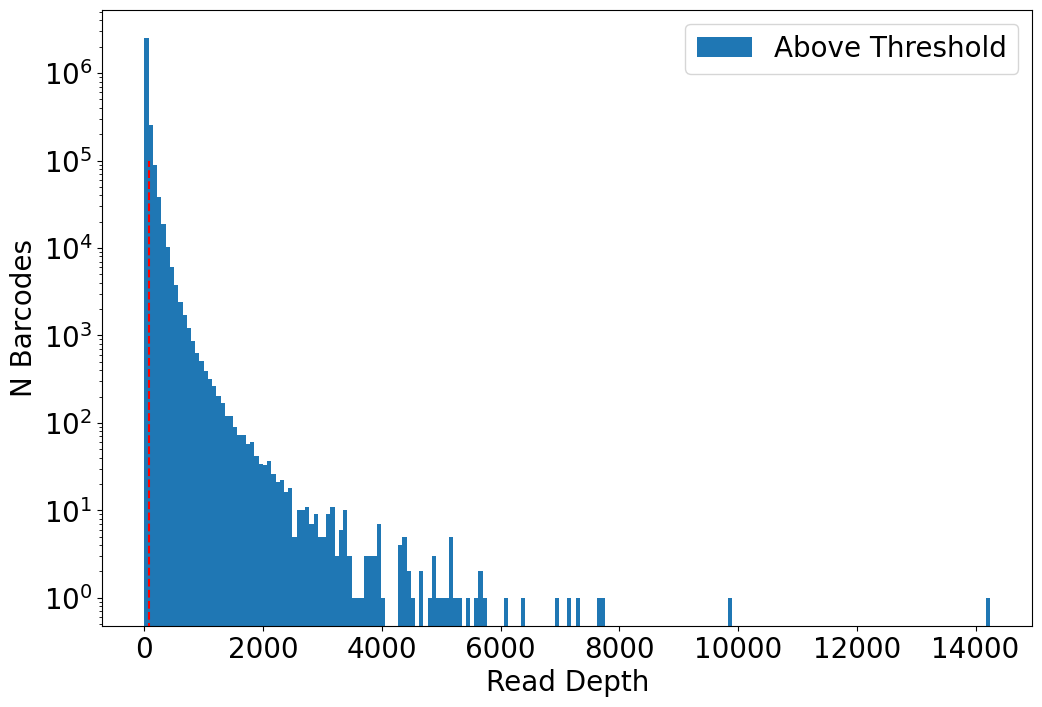

In [27]:
fig = plt.figure(figsize=(12, 8))

threshold = 70

# under_threshold_arr = depth_arr[depth_arr < threshold]
above_threshold_arr = depth_arr# depth_arr[depth_arr >= threshold]
# plt.hist(
#     under_threshold_arr,
#     bins=200,
#     range=(0, 25000),
#     log=True,
#     color="grey",
#     label="Under Threshold",
# )

plt.hist(
    above_threshold_arr,
    bins=200,
    # range=(0, 200),
    log=True,
    color="tab:blue",
    label="Above Threshold",
)
plt.xlabel("Read Depth", fontsize=20)
plt.xticks(fontsize=20)
plt.ylabel("N Barcodes", fontsize=20)
plt.yticks(fontsize=20)
plt.legend(fontsize=20)
plt.vlines(threshold, 0, 100000, color="red", linestyle="--")
plt.savefig("./depth_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Draw a vertical line at the threshold


In [ ]:
## START OF DEBUGGING

In [ ]:
_ = plt.hist(data[data["closest_match"] == 1]["barcode depth"],bins=100,range=(0,2500),density=True,alpha=0.5)
_ = plt.hist(data[data["closest_match"]>3]["barcode depth"],bins=100,range=(0,2500),density=True,alpha=0.5)

In [ ]:
# END OF DEBUGGING

In [28]:
aDE12_Variant = 'ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAACGAAAGGCCCAGTCTTTCGACTGAGCCTTTCGTTTTATTTGATGCCTCTAGCAGCACCGACTCGGTGCCACTTTTTCAAGTTGATAACGGACTAGCCTTATTTTAACTTGCTATTTCTAGCTCTAAAACNNNNNNNNNNNNNNNNNNNNACTAGTATTATACCTAGGACTGAGCTAGCTGTCAATACATAATACGACTCACTATAGGGACGAACGTTAGCAGCACTATNNNNNNNNNNNNNNNNNNNNACAGTAACGTTAGCTAGCCTC'
sgRNA = aDE12_Variant[175:195]
UMI = aDE12_Variant[274:294]
print(sgRNA, UMI)

lLAG8_Variant = 'ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAACGAAAGGCCCAGTCTTTCGACTGAGCCTTTCGTTTTATTTGATGCCTCTAGCAGCACCGACTCGGTGCCACTTTTTCAAGTTGATAACGGACTAGCCTTATTTTAACTTGCTATTTCTAGCTCTAAAACNNNNNNNNNNNNNNNNNNNNACATTTATTGTACAACACGAGCCCATTTTTTACATTACATAATACGACTCACTATAGGGGAATTGTGAGCGGATAACAATTCCCCTCTAGAACAGAATAGTCTTTTAAGTAAGTCTACTCTGAATTTTTTTAAAAGGAGAGGGTAAAGAGTGAGAAGCAAATAAACGAACGTTAGCAGCACTATNNNNNNNNNNNNNNNNNNNNACAGTAACGTTAGCTAGCCTC'
sgRNA = lLAG8_Variant[175:195]
UMI = lLAG8_Variant[379:399]
print(sgRNA, UMI)

NNNNNNNNNNNNNNNNNNNN NNNNNNNNNNNNNNNNNNNN
NNNNNNNNNNNNNNNNNNNN NNNNNNNNNNNNNNNNNNNN


In [29]:
# data_df = dd.from_pandas(data, npartitions=100).persist()
data_df = data.copy(deep=True)
## Align consensus sequence to reference using cigar string
aligned_cons = data_df.apply(lambda x: align_read(x["consensus"],x["reference"],x["cigar"],startpos=x["alignmentstart"]), axis=1)

## Use GFA reference to determine intervals for each annotation 
ref_intervals = get_ref_intervals(headpath+"ref_lLAG8.gfa")
## Split sequences based on annotated intervals
split_ref = data_df.apply(lambda x: splitstr(x["reference"],ref_intervals), axis=1)
split_align = aligned_cons.apply(lambda x: splitstr(x,ref_intervals))

data_df["aligned_cons"] = aligned_cons
data_df["split_ref"] = split_ref
data_df["split_align"] = split_align



## Compute hamming distance from reference, by annotated element
hamm_ref = data_df.apply(lambda x: get_dict_dist(x["split_align"],x["split_ref"]), axis=1)

## Get promoters and UMIs
# UMI = data_df["split_align"].apply(lambda x: x["Variant"][274:294], meta=str).persist()
UMI = data_df["split_align"].apply(lambda x: x["Variant"][379:399])

sgRNA = data_df["split_align"].apply(lambda x: str(Seq(x["Variant"][175:195]).reverse_complement()))


## Assign closest match to each barcode (for costructing output df later)
closest_hamming_dist = data_df["barcode"].apply(lambda x: closest_match_dict[x])

data_df["hamm_ref"] = hamm_ref
data_df["UMI"] = UMI
data_df["sgRNA"] = sgRNA
data_df["Closest Hamming Distance"] = closest_hamming_dist

del hamm_ref
del closest_hamming_dist
del aligned_cons
del split_align
del split_ref

In [30]:
data_df.to_pickle(headpath+"2025-05-14_lLAG10_final_df_before-gRNAs.pkl")

In [8]:
data_df = pd.read_pickle(headpath + "2025-05-14_lLAG10_final_df_before-gRNAs.pkl")

### Frequency Distributions

In [ ]:
# import pandas as pd
# pd.read_csv("./lLAG2_final_df.tsv", sep="\t").to_csv("./lLAG2_final_df_V2.tsv", sep = "\t", index=True)

<AxesSubplot:>

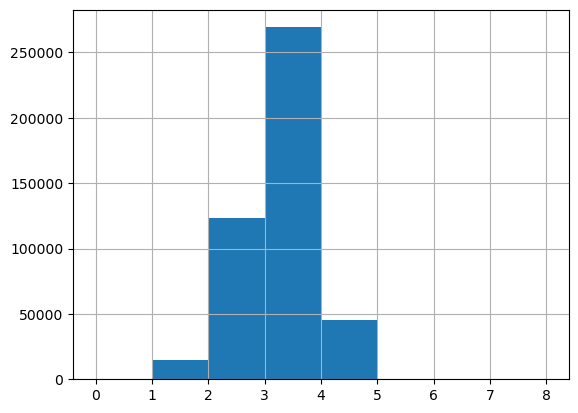

In [9]:
data_df.loc[:,'Closest Hamming Distance'].hist(bins=range(0,9))

In [ ]:
# data_df = (pd.read_csv(
#     "/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/lLAG8_final_df.tsv",
#     delimiter="\t",
# ).drop(columns=["Unnamed: 0"]))
# # Remoive the unnamed column

## Below here only for gRNA stuff

### Frequency Distributions

In [10]:
print(data_df['sgRNA'].nunique())
print(data_df['sgRNA'].str.contains('N').sum())
#print the difference
print(data_df['sgRNA'].nunique() - data_df['sgRNA'].str.contains('N').sum())

# Print the number on the sgRNA data

19749
3920
15829


<AxesSubplot:>

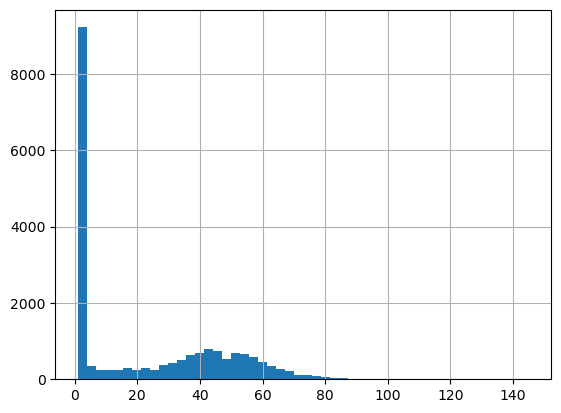

In [11]:
n_barcodes = data_df.groupby("sgRNA").size()
n_barcodes.hist(bins=50)

In [ ]:
# # DE
# de_sgRNA_data = pd.read_csv("/home/lag36/scratch/lag36/2023-03-10_lDE26_Nanopore/2021-04-20_Essential_KO_Lib_df_coords_corrected.tsv",sep="\t")
# de_sgRNA_data = de_sgRNA_data[(de_sgRNA_data["Category"] != "OnlyChr")&(de_sgRNA_data["Category"] != "NonEssentialOnlyChr")]
# # de_sgRNA_data[de_sgRNA_data['Category'] == 'NoTarget']
# de_sgRNA_data

In [12]:
import pandas as pd
from Bio.Seq import Seq
import numpy as np

In [26]:
pd.read_pickle(headpath + 'df_non_to_order_all.pkl').reset_index(drop=True)

,index,locus_tag,gene,bin_index,n_off_targets,n_nts_mismatched,binds_non_template_strand_off_target,strand,n,offset,...,start_off_target,end_off_target,selected,bin_index_assigned,gene_category,relative_fitness_mean,relative_fitness_std,category,seq_to_order,seq_to_order_with_suffixes
0,4.0,BSU_00030,yaaA,9.0,0,NaN,<NA>,1,5.0,147.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
1,3.0,BSU_00030,yaaA,9.0,1,10.0,<NA>,1,4.0,144.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
2,2.0,BSU_00030,yaaA,9.0,1,6.0,<NA>,1,3.0,136.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
3,5.0,BSU_00040,recF,9.0,0,NaN,<NA>,1,1.0,12.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
4,37.0,BSU_00040,recF,9.0,0,NaN,<NA>,1,36.0,704.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11366,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,NaN,...,3194872,3195262,False,NaN,control,0.987210,0.016695,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11367,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,NaN,...,3279958,3281104,False,NaN,control,1.005779,0.008596,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11368,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,NaN,...,1162360,1163422,False,NaN,control,0.994731,0.020760,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11369,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,NaN,...,1712454,1714122,False,NaN,control,1.028080,0.015783,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...


In [14]:
# ONLY NEEDED ONCE: GET RID OF WEIRD INDEX IN lLAG10
pd.read_pickle("/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/df_ess_to_order_all.pkl")

,locus_tag,gene,bin_index_fitness,bin_index,n_off_targets,n_nts_mismatched,binds_non_template_strand_off_target,query_spacer,full_sgrna,pam,...,downstream,sequence,off_target_n,gc_downstream_8_9,n_off_target_tRNA,n_off_target_other,n_off_target_rRNA,category,seq_to_order,seq_to_order_with_suffixes
0,BSU_00010,dnaA,9.0,0.0,3,9.0,False,CTTAATGCTCAATTCTTCCA,CTTAATGCTCAATTCTTCCC,CGG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
4,BSU_00010,dnaA,9.0,1.0,0,NaN,<NA>,CTAATATATTTTCCATCTTT,CTAATATATTTTCCATCTTC,CGG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
6,BSU_00010,dnaA,8.0,1.0,1,8.0,False,TTCATCCAAGTCTCAAAACA,TTCATCCAAGTCTCAAAACT,CGG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
10,BSU_00010,dnaA,9.0,2.0,0,NaN,<NA>,TGCAATCAGATGCAAGTATG,TGCAATCAGATGCAAGTATC,TGG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
15,BSU_00010,dnaA,9.0,3.0,0,NaN,<NA>,GCCTTGCAGTGAGTGGGCTC,GCCTTGCAGTGAGTGGGCTT,TGG,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
407,NaN,NaN,NaN,NaN,1,9.0,True,CTCACCTCCAGCACAGCTCC,CTCACCTCCAGCACAGCTCC,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
419,NaN,NaN,NaN,NaN,1,9.0,True,CTGCCGGGACATCTCCCCAG,CTGCCGGGACATCTCCCCAG,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
436,NaN,NaN,NaN,NaN,1,9.0,True,CTTGTGTGGGCGTGCCCGAA,CTTGTGTGGGCGTGCCCGAA,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
438,NaN,NaN,NaN,NaN,1,9.0,True,CTTTACCCACGAGCAGCTAA,CTTTACCCACGAGCAGCTAA,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...


,opLAG1_id,index,locus_tag,gene,bin_index,n_off_targets,n_nts_mismatched,binds_non_template_strand_off_target,strand,n,...,start_off_target,end_off_target,selected,bin_index_assigned,gene_category,relative_fitness_mean,relative_fitness_std,category,seq_to_order,seq_to_order_with_suffixes
0,0,4.0,BSU_00030,yaaA,9.0,0,NaN,<NA>,1,5.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
1,1,3.0,BSU_00030,yaaA,9.0,1,10.0,<NA>,1,4.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
2,2,2.0,BSU_00030,yaaA,9.0,1,6.0,<NA>,1,3.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
3,3,5.0,BSU_00040,recF,9.0,0,NaN,<NA>,1,1.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
4,4,37.0,BSU_00040,recF,9.0,0,NaN,<NA>,1,36.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11366,11366,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,3194872,3195262,False,NaN,control,0.987210,0.016695,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11367,11367,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,3279958,3281104,False,NaN,control,1.005779,0.008596,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11368,11368,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,1162360,1163422,False,NaN,control,0.994731,0.020760,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11369,11369,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,1712454,1714122,False,NaN,control,1.028080,0.015783,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...


In [31]:
# # LUIS' VERSION FOR MERGING WITH LIBRARY DESIGN TABLE

# Formatting sgRNA data to make it similar to Daniel's format (for df_non_to_order_all.pkl)
sgRNA_data = \
    (pd
     .read_pickle(headpath + 'df_non_to_order_all.pkl')
     .reset_index(drop=True)
     # .drop(columns = ['level_0'])
     .reset_index()
     .rename(columns={'level_0': 'opLAG1_id'})
    )
# sgRNA_data = sgRNA_data[(sgRNA_data["Category"] != "OnlyChr")&(sgRNA_data["Category"] != "NonEssentialOnlyChr")]
sgRNA_data

# # Formatting sgRNA data to make it similar to Daniel's format (for df_ess_to_order_all.pkl)
# sgRNA_data = \
#     (pd
#      .read_pickle("/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/df_ess_to_order_all.pkl")
#      .reset_index()
#      # .drop(columns = ['level_0'])
#      .reset_index()
#      .rename(columns={'level_0': 'opLAG1_id'})
#     )
# # sgRNA_data = sgRNA_data[(sgRNA_data["Category"] != "OnlyChr")&(sgRNA_data["Category"] != "NonEssentialOnlyChr")]
# sgRNA_data

,opLAG1_id,index,locus_tag,gene,bin_index,n_off_targets,n_nts_mismatched,binds_non_template_strand_off_target,strand,n,...,start_off_target,end_off_target,selected,bin_index_assigned,gene_category,relative_fitness_mean,relative_fitness_std,category,seq_to_order,seq_to_order_with_suffixes
0,0,4.0,BSU_00030,yaaA,9.0,0,NaN,<NA>,1,5.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
1,1,3.0,BSU_00030,yaaA,9.0,1,10.0,<NA>,1,4.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
2,2,2.0,BSU_00030,yaaA,9.0,1,6.0,<NA>,1,3.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
3,3,5.0,BSU_00040,recF,9.0,0,NaN,<NA>,1,1.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
4,4,37.0,BSU_00040,recF,9.0,0,NaN,<NA>,1,36.0,...,<NA>,<NA>,True,9,nonessential,NaN,NaN,NaN,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11366,11366,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,3194872,3195262,False,NaN,control,0.987210,0.016695,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11367,11367,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,3279958,3281104,False,NaN,control,1.005779,0.008596,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11368,11368,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,1162360,1163422,False,NaN,control,0.994731,0.020760,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...
11369,11369,NaN,NaN,NaN,NaN,1,9.0,True,NaN,NaN,...,1712454,1714122,False,NaN,control,1.028080,0.015783,control,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...,CGTACGACGGAAGACATTCTCCTGTAATGTAAAAAATGGGCTCGTG...


In [37]:
sgRNA_data

,opLAG1_id,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID
0,0,BSU_00030,147.0,yaaA,CAACATACAGCTTTCTGCCC,GGGCAGAAAGCTGTATGTTG,nonessential,1.0,0
1,1,BSU_00030,144.0,yaaA,CATACAGCTTTCTGCCCCGG,CCGGGGCAGAAAGCTGTATG,nonessential,1.0,1
2,2,BSU_00030,136.0,yaaA,TTTCTGCCCCGGCGGTTGTC,GACAACCGCCGGGGCAGAAA,nonessential,1.0,2
3,3,BSU_00040,12.0,recF,AAGATGTCAGTTCTAAGTTC,GAACTTAGAACTGACATCTT,nonessential,1.0,3
4,4,BSU_00040,704.0,recF,TCCTATTTTCGACAAATCTA,TAGATTTGTCGAAAATAGGA,nonessential,1.0,4
...,...,...,...,...,...,...,...,...,...
11366,11366,NaN,NaN,NaN,CTCACCTCCAGCACAGCTCC,GGAGCTGTGCTGGAGGTGAG,control,NaN,11366
11367,11367,NaN,NaN,NaN,CTGCCGGGACATCTCCCCAG,CTGGGGAGATGTCCCGGCAG,control,NaN,11367
11368,11368,NaN,NaN,NaN,CTTGTGTGGGCGTGCCCGAA,TTCGGGCACGCCCACACAAG,control,NaN,11368
11369,11369,NaN,NaN,NaN,CTTTACCCACGAGCAGCTAA,TTAGCTGCTCGTGGGTAAAG,control,NaN,11369


In [39]:

sgRNA_data_condensed = (sgRNA_data
 .reset_index()
 # rename index to opLAG1_id
 .rename(columns={#"index":"opLAG1_id",
                  "gene":"Gene",
                  "gene_category":"Category",
                  "predicted_efficacy":"Predicted_Efficacy",})
#  .assign(sgRNA_Sequence = lambda df_: df_["query_spacer"]) # for essentials
 .assign(sgRNA_Sequence = lambda df_: df_["sgRNA Sequence"]) # for nonessentials
 # Assign to Target_Sequence the result of the reverse complement of the full_sgrna
 .assign(Target_Sequence = lambda df_: df_["Target Sequence"])
#  .assign(Target_Sequence = lambda df_: df_['full_sgrna'].apply(lambda x: str(Seq(x).reverse_complement()))) # for essentials
#  .assign(Target_Sequence = lambda df_: df_['full_sgrna'])
#  assign(.apply(lambda x: str(Seq(x["Variant"][175:195]).reverse_complement())
# assign a column that has a unique index for every gene, offset pair
 .loc[:, ["opLAG1_id","locus_tag","offset", "Gene","sgRNA_Sequence","Target_Sequence", "Category", "Predicted_Efficacy"]]
 .merge(sgRNA_data[['locus_tag', 'offset']]
        .groupby(["locus_tag", "offset"], sort = False)
        .first()
        .reset_index()
        .reset_index()
        .rename(columns={"index":"TargetID"}),
        how = 'left', on=["locus_tag", "offset"]
        )
)
        
sgRNA_data_condensed.loc[sgRNA_data_condensed['TargetID'].isna(), 'TargetID'] =  np.arange(sgRNA_data_condensed['TargetID'].max()+1, sgRNA_data_condensed['TargetID'].max() +1+ sgRNA_data_condensed['TargetID'].isna().sum())
sgRNA_data_condensed = (sgRNA_data_condensed
                        .astype({"TargetID":int})
                        .rename(columns = {"sgRNA_Sequence":"sgRNA Sequence",
                                           "Target_Sequence":"Target Sequence"})
)

sgRNA_data = sgRNA_data_condensed


sgRNA_dict = sgRNA_data["sgRNA Sequence"].to_dict()
sgRNA_inv_dict = {val: key for key, val in sgRNA_dict.items()}


valid_mask = data_df["sgRNA"].isin(sgRNA_inv_dict.keys())
valid_data_df = data_df[valid_mask]

index_map = valid_data_df["sgRNA"].apply(lambda x: sgRNA_inv_dict[x])
sgRNA_data_subset = sgRNA_data.loc[index_map.to_list()]

merged_df = valid_data_df.reset_index(drop=True).join(sgRNA_data_subset.reset_index(drop=True))
merged_df["barcode depth"] = merged_df["barcode"].apply(lambda x: depth_dict[x])

In [40]:
merged_df

,barcodeid,barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,aligned_cons,...,Closest Hamming Distance,opLAG1_id,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID
0,1,000000000000000000001101111011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,215,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,1395,BSU_05660,45.0,ydgI,GATCATAGTTGCGGATAGAA,TTCTATCCGCAACTATGATC,nonessential,1.0,1395
1,2,000000000000000000100101010101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,925M1I166M,NaN,119,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,4617,BSU_17200,5179.0,pksM,AGCGCCTTCATAGCCTCCGC,GCGGAGGCTATGAAGGCGCT,nonessential,1.0,4617
2,3,000000000000000001010010100010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,130,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,6432,BSU_25440,710.0,yqeU,ACTCAACGCGTATAGCGGAG,CTCCGCTATACGCGTTGAGT,nonessential,1.0,6432
3,4,000000000000000001100011111000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,83,2,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,2,7525,BSU_29410,420.0,ytkL,AAAGTGCCGTATCGCCCGCG,CGCGGGCGATACGGCACTTT,nonessential,1.0,7525
4,5,000000000000000010001101000111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,266,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,2095,BSU_08110,136.0,sspH,TGCACTTCATGCTCCTCTTG,CAAGAGGAGCATGAAGTGCA,nonessential,1.0,2095
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444132,452938,111111111000110001010001111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,379M1I184M1I395M1I133M,NaN,71,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,8043,BSU_31270,680.0,tgl,GGTCGCCTGAGACAGAAGGT,ACCTTCTGTCTCAGGCGACC,nonessential,1.0,8043
444133,452939,111111111001001011011011000000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,560M2D529M,NaN,88,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,687,BSU_02980,354.0,opuAA,GCGGAAACAGAGCGAACTTT,AAAGTTCGCTCTGTTTCCGC,nonessential,1.0,687
444134,452940,111111111001101101111011100100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,575M1I516M,NaN,85,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,603,BSU_02710,245.0,yczC,ACGGACAATGGCTTGCGGGA,TCCCGCAAGCCATTGTCCGT,nonessential,1.0,603
444135,452941,111111111101100000001011111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,379M1D201M1I510M,NaN,103,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,8114,BSU_31480,669.0,yuxJ,CATATAAAGCGAGCAGGGGC,GCCCCTGCTCGCTTTATATG,nonessential,1.0,8114


In [ ]:
# DANIEL'S VERSION FOR MERGING WITH LIBRARY DESIGN TABLE

# sgRNA_data = pd.read_csv(
#     "/home/de64/group/nanopore/dev_notebooks/2023-03-19_snakemake_lDE23/2021-04-20_Essential_KO_Lib_df_coords_corrected.tsv",
#     sep="\t",
# )
# sgRNA_data = sgRNA_data[
#     (sgRNA_data["Category"] != "OnlyChr")
#     & (sgRNA_data["Category"] != "NonEssentialOnlyChr")
# ]

# sgRNA_dict = sgRNA_data["sgRNA Sequence"].to_dict()
# sgRNA_inv_dict = {val: key for key, val in sgRNA_dict.items()}

# valid_mask = data_df["sgRNA"].isin(sgRNA_inv_dict.keys())
# valid_data_df = data_df[valid_mask]
# index_map = valid_data_df["sgRNA"].apply(lambda x: sgRNA_inv_dict[x])
# sgRNA_data_subset = sgRNA_data.loc[index_map.to_list()]

# merged_df = valid_data_df.reset_index(drop=True).join(
#     sgRNA_data_subset[
#         [
#             "oDEPool7_id",
#             "EcoWG1_id",
#             "Gene",
#             "Strand",
#             "Target Sequence",
#             "Target Sites",
#             "N Target Sites",
#             "N Mismatch",
#             "Category",
#             "TargetID",
#         ]
#     ].reset_index(drop=True)
# )
# merged_df["barcode depth"] = merged_df["barcode"].apply(lambda x: depth_dict[x])

In [41]:
merged_df.to_pickle(headpath+"2025-05-14_lLAG10_final_df_merged-sgRNAs.pkl")

In [52]:
pd.read_pickle(headpath+"2025-05-14_lLAG10_final_df_merged-sgRNAs.pkl")

,barcodeid,barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,aligned_cons,...,Closest Hamming Distance,opLAG1_id,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID
0,1,000000000000000000001101111011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,215,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,1395,BSU_05660,45.0,ydgI,GATCATAGTTGCGGATAGAA,TTCTATCCGCAACTATGATC,nonessential,1.0,1395
1,2,000000000000000000100101010101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,925M1I166M,NaN,119,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,4617,BSU_17200,5179.0,pksM,AGCGCCTTCATAGCCTCCGC,GCGGAGGCTATGAAGGCGCT,nonessential,1.0,4617
2,3,000000000000000001010010100010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,130,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,6432,BSU_25440,710.0,yqeU,ACTCAACGCGTATAGCGGAG,CTCCGCTATACGCGTTGAGT,nonessential,1.0,6432
3,4,000000000000000001100011111000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,83,2,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,2,7525,BSU_29410,420.0,ytkL,AAAGTGCCGTATCGCCCGCG,CGCGGGCGATACGGCACTTT,nonessential,1.0,7525
4,5,000000000000000010001101000111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,1091M,NaN,266,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,2095,BSU_08110,136.0,sspH,TGCACTTCATGCTCCTCTTG,CAAGAGGAGCATGAAGTGCA,nonessential,1.0,2095
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444132,452938,111111111000110001010001111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,379M1I184M1I395M1I133M,NaN,71,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,8043,BSU_31270,680.0,tgl,GGTCGCCTGAGACAGAAGGT,ACCTTCTGTCTCAGGCGACC,nonessential,1.0,8043
444133,452939,111111111001001011011011000000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,560M2D529M,NaN,88,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,687,BSU_02980,354.0,opuAA,GCGGAAACAGAGCGAACTTT,AAAGTTCGCTCTGTTTCCGC,nonessential,1.0,687
444134,452940,111111111001101101111011100100,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,575M1I516M,NaN,85,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,603,BSU_02710,245.0,yczC,ACGGACAATGGCTTGCGGGA,TCCCGCAAGCCATTGTCCGT,nonessential,1.0,603
444135,452941,111111111101100000001011111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1,379M1D201M1I510M,NaN,103,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,8114,BSU_31480,669.0,yuxJ,CATATAAAGCGAGCAGGGGC,GCCCCTGCTCGCTTTATATG,nonessential,1.0,8114


#### Add fiducial markers

In [46]:
def slow_hamming_distance(s1, s2):
    '''
    Etimates the hamming distance between two barcodes that are represented in binary
    '''
    if len(s1) != len(s2):
        print(s1,s2)
        raise ValueError("Strand lengths are not equal!")
    term_list = []
    for ch1,ch2 in zip(s1,s2):
        if ch1 == "N" or ch2 == "N":
            term_list.append(False)
        else:
            term_list.append(ch1 != ch2)
    result = sum(term_list)
    return result

In [47]:
barcode_list = merged_df['barcode']

In [48]:
# Change: Fiducial barcodes that I have made
fiducial_barcodes = ['1'*30, # LAG540
                     '01'*15, # LAG544
                     '10'*15, # LAG550
                    ]

In [49]:
# Get hamming distance matrix (for 2 barcodes)
hamming_distance_matrix = np.zeros((len(fiducial_barcodes), len(fiducial_barcodes)))
for i, barcode_1 in enumerate(fiducial_barcodes):
    for j, barcode_2 in enumerate(fiducial_barcodes):
        hamming_distance_matrix[i,j] = slow_hamming_distance(barcode_1, barcode_2)

# Place infinity in the diagonal
np.fill_diagonal(hamming_distance_matrix, np.inf)

# Get the min hamming distances across all fiducials
min_ham_distance_fiducials = np.min(hamming_distance_matrix, axis=1).astype(int)

# Get the list of closest hamming distances for each barcode
closest_hamming_distance = np.zeros(len(fiducial_barcodes), dtype=int)
for i, barcode in enumerate(fiducial_barcodes):
    print(i, barcode)
    closest_hamming_distance[i] = np.min([merged_df.apply(lambda x: slow_hamming_distance(x["barcode"], barcode), axis=1).min(), min_ham_distance_fiducials[i]])



0 111111111111111111111111111111
1 010101010101010101010101010101
2 101010101010101010101010101010


In [ ]:
data

In [50]:
pd.DataFrame({"barcode":fiducial_barcodes,
                                         "Closest Hamming Distance":closest_hamming_distance,
                                         "barcodeid": np.arange(len(fiducial_barcodes)) + merged_df['barcodeid'].max() + 1,
                                         "closest_match": closest_hamming_distance,
                                         "Category": ["fiducial"]*len(fiducial_barcodes)
                                        })

,barcode,Closest Hamming Distance,barcodeid,closest_match,Category
0,111111111111111111111111111111,3,452943,3,fiducial
1,010101010101010101010101010101,4,452944,4,fiducial
2,101010101010101010101010101010,4,452945,4,fiducial


In [53]:
merged_df_fid = \
    (pd.concat([merged_df, pd.DataFrame({"barcode":fiducial_barcodes,
                                         "Closest Hamming Distance":closest_hamming_distance,
                                         "barcodeid": np.arange(len(fiducial_barcodes)) + merged_df['barcodeid'].max() + 1,
                                         "closest_match": closest_hamming_distance,
                                         "Category": ["fiducial"]*len(fiducial_barcodes)
                                        })
               ])
     .reset_index(drop=True)
    )

In [54]:
merged_df_fid

,barcodeid,barcode,consensus,reference,alignmentstart,cigar,subsample,barcode depth,closest_match,aligned_cons,...,Closest Hamming Distance,opLAG1_id,locus_tag,offset,Gene,sgRNA Sequence,Target Sequence,Category,Predicted_Efficacy,TargetID
0,1,000000000000000000001101111011,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,215.0,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,1395.0,BSU_05660,45.0,ydgI,GATCATAGTTGCGGATAGAA,TTCTATCCGCAACTATGATC,nonessential,1.0,1395.0
1,2,000000000000000000100101010101,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,925M1I166M,NaN,119.0,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,4617.0,BSU_17200,5179.0,pksM,AGCGCCTTCATAGCCTCCGC,GCGGAGGCTATGAAGGCGCT,nonessential,1.0,4617.0
2,3,000000000000000001010010100010,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,130.0,3,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,3,6432.0,BSU_25440,710.0,yqeU,ACTCAACGCGTATAGCGGAG,CTCCGCTATACGCGTTGAGT,nonessential,1.0,6432.0
3,4,000000000000000001100011111000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,83.0,2,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,2,7525.0,BSU_29410,420.0,ytkL,AAAGTGCCGTATCGCCCGCG,CGCGGGCGATACGGCACTTT,nonessential,1.0,7525.0
4,5,000000000000000010001101000111,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,266.0,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,2095.0,BSU_08110,136.0,sspH,TGCACTTCATGCTCCTCTTG,CAAGAGGAGCATGAAGTGCA,nonessential,1.0,2095.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
444135,452941,111111111101100000001011111110,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,379M1D201M1I510M,NaN,103.0,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,8114.0,BSU_31480,669.0,yuxJ,CATATAAAGCGAGCAGGGGC,GCCCCTGCTCGCTTTATATG,nonessential,1.0,8114.0
444136,452942,111111111101111111110001001000,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,1.0,1091M,NaN,120.0,4,ATTTGTCCTACTCAGGAGAGCGTTCACCGACAAACAACAGATAAAA...,...,4,11028.0,NaN,NaN,NaN,GACGCAAAGAATTTCGACCA,TGGTCGAAATTCTTTGCGTC,control,NaN,11028.0
444137,452943,111111111111111111111111111111,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,...,3,NaN,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN
444138,452944,010101010101010101010101010101,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,...,4,NaN,NaN,NaN,NaN,NaN,NaN,fiducial,NaN,NaN


In [55]:
merged_df_fid.to_pickle(headpath+"2025-05-14_lLAG10_final_df_merged-sgRNAs-fiducials.pkl")

In [ ]:
# merged_df_fid.to_pickle("/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials.pkl")

In [ ]:
# merged_df_fid = pd.read_pickle("/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials.pkl")

In [56]:
merged_df_fid.to_csv(headpath+"2025-05-14_lLAG10_final_df_merged-sgRNAs-fiducials.tsv",
                     sep = "\t",
                     index = False)

In [60]:
merged_df_fid.to_csv(headpath+"2025-05-14_lLAG10_final_df_merged-sgRNAs-fiducials_with-index.tsv",
                     sep = "\t",
                     index = True)

In [ ]:
# merged_df_fid.to_csv("/home/lag36/scratch/lag36/2024-08-26_lLAG8_Nanopore/2025-03-24_lLAG8_final_df_merged-sgRNAs-fiducials.tsv",
#                      sep = "\t",
#                      index = False)